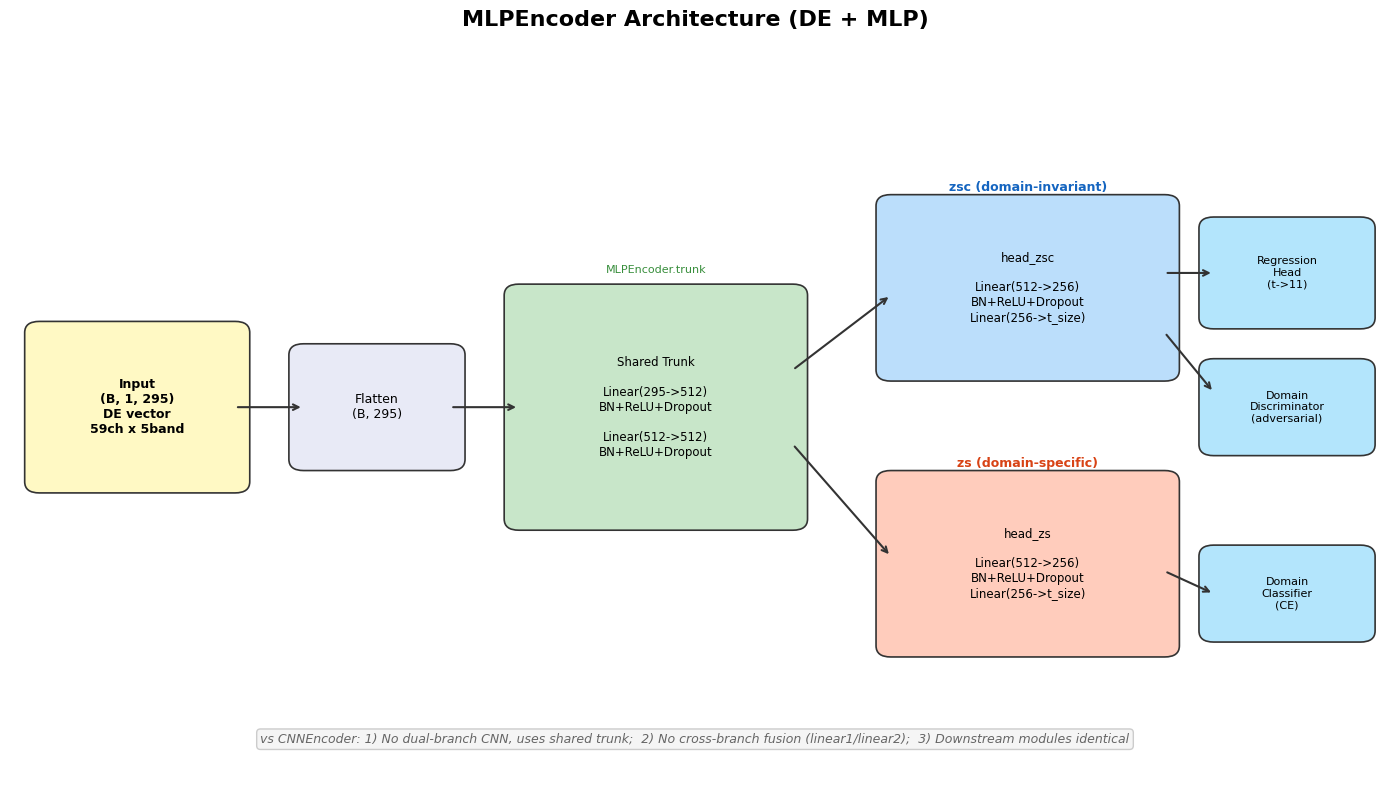

Diagram saved to /root/zjm/cadt_test_code/report/04.mlp_encoder_structure.png


In [7]:
# === Cell 1: MLPEncoder Architecture Diagram ===
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

fig, ax = plt.subplots(1, 1, figsize=(14, 8))
ax.set_xlim(0, 14)
ax.set_ylim(0, 10)
ax.axis('off')
ax.set_title('MLPEncoder Architecture (DE + MLP)', fontsize=16, fontweight='bold')

def draw_box(ax, x, y, w, h, text, color='#E3F2FD', fontsize=9, fontweight='normal'):
    rect = mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.15",
                                    facecolor=color, edgecolor='#333', linewidth=1.2)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, ha='center', va='center',
            fontsize=fontsize, fontweight=fontweight)

def draw_arrow(ax, x1, y1, x2, y2):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color='#333', lw=1.5))

# Input
draw_box(ax, 0.3, 4.0, 2.0, 2.0, 'Input\n(B, 1, 295)\nDE vector\n59ch x 5band', color='#FFF9C4', fontsize=9, fontweight='bold')

# Flatten
draw_box(ax, 3.0, 4.3, 1.5, 1.4, 'Flatten\n(B, 295)', color='#E8EAF6', fontsize=9)

# Trunk
draw_box(ax, 5.2, 3.5, 2.8, 3.0,
         'Shared Trunk\n\nLinear(295->512)\nBN+ReLU+Dropout\n\nLinear(512->512)\nBN+ReLU+Dropout',
         color='#C8E6C9', fontsize=8.5)
ax.text(6.6, 6.8, 'MLPEncoder.trunk', ha='center', fontsize=8, color='#388E3C')

# Branch arrows
draw_arrow(ax, 2.3, 5.0, 3.0, 5.0)
draw_arrow(ax, 4.5, 5.0, 5.2, 5.0)
draw_arrow(ax, 8.0, 5.5, 9.0, 6.5)
draw_arrow(ax, 8.0, 4.5, 9.0, 3.0)

# head_zsc
draw_box(ax, 9.0, 5.5, 2.8, 2.2,
         'head_zsc\n\nLinear(512->256)\nBN+ReLU+Dropout\nLinear(256->t_size)',
         color='#BBDEFB', fontsize=8.5)
ax.text(10.4, 7.9, 'zsc (domain-invariant)', ha='center', fontsize=9, fontweight='bold', color='#1565C0')

# head_zs
draw_box(ax, 9.0, 1.8, 2.8, 2.2,
         'head_zs\n\nLinear(512->256)\nBN+ReLU+Dropout\nLinear(256->t_size)',
         color='#FFCCBC', fontsize=8.5)
ax.text(10.4, 4.2, 'zs (domain-specific)', ha='center', fontsize=9, fontweight='bold', color='#D84315')

# Downstream
draw_box(ax, 12.3, 6.2, 1.5, 1.2, 'Regression\nHead\n(t->11)', color='#B3E5FC', fontsize=8)
draw_box(ax, 12.3, 4.5, 1.5, 1.0, 'Domain\nDiscriminator\n(adversarial)', color='#B3E5FC', fontsize=8)
draw_box(ax, 12.3, 2.0, 1.5, 1.0, 'Domain\nClassifier\n(CE)', color='#B3E5FC', fontsize=8)

draw_arrow(ax, 11.8, 6.8, 12.3, 6.8)
draw_arrow(ax, 11.8, 6.0, 12.3, 5.2)
draw_arrow(ax, 11.8, 2.8, 12.3, 2.5)

# vs CNN note
ax.text(7.0, 0.5, 'vs CNNEncoder: 1) No dual-branch CNN, uses shared trunk;  2) No cross-branch fusion (linear1/linear2);  3) Downstream modules identical',
        ha='center', fontsize=9, style='italic', color='#666',
        bbox=dict(boxstyle='round', facecolor='#F5F5F5', edgecolor='#CCC'))

plt.tight_layout()
plt.savefig('/root/zjm/cadt_test_code/report/04.mlp_encoder_structure.png', dpi=150, bbox_inches='tight')
plt.show()
print("Diagram saved to /root/zjm/cadt_test_code/report/04.mlp_encoder_structure.png")


In [8]:
# === Cell 2: 解析所有实验结果 ===
import os, re, json
import pandas as pd
import numpy as np

def parse_results(results_path):
    """解析 results.txt，返回指标字典"""
    with open(results_path, 'r') as f:
        text = f.read()
    
    def extract(key):
        m = re.search(rf'^{re.escape(key)}.*?:\s*([\d.\-eE]+)', text, re.MULTILINE)
        return float(m.group(1)) if m else None
    
    split_mode_m = re.search(r'^Split Mode:\s*(\S+)', text, re.MULTILINE)
    ablation_m = re.search(r'^Ablation:\s*(\S+)', text, re.MULTILINE)
    encoder_m = re.search(r'^Encoder:\s*(\S+)', text, re.MULTILINE)
    tsize_m = re.search(r'^t_size:\s*(\d+)', text, re.MULTILINE)
    target_sub_m = re.search(r'^Target Subject:\s*(.+)', text, re.MULTILINE)
    
    return {
        'split_mode': split_mode_m.group(1) if split_mode_m else 'unknown',
        'ablation': ablation_m.group(1) if ablation_m else 'none',
        'encoder': encoder_m.group(1) if encoder_m else 'cnn',
        't_size': int(tsize_m.group(1)) if tsize_m else 8,
        'target_subject': target_sub_m.group(1).strip() if target_sub_m else 'all',
        'test_mse': extract('Test MSE'),
        'test_mae': extract('Test MAE'),
        'test_rmse': extract('Test RMSE'),
        'test_r2': extract('Test R2'),
        'test_avg_r2': extract('Test Avg R2'),
        'test_pearson': extract('Test Pearson'),
        'test_spearman': extract('Test Spearman'),
        'val_r2': extract('Val R2'),
        'val_avg_r2': extract('Val Avg R2'),
    }

def scan_dir(base_dir, label, exclude_dirs=None):
    """扫描目录下所有实验结果"""
    if exclude_dirs is None:
        exclude_dirs = []
    results = []
    # 递归查找 results.txt
    for root, dirs, files in os.walk(base_dir):
        # 检查当前路径是否包含要排除的目录
        path_parts = root.split(os.sep)
        if any(ex in path_parts for ex in exclude_dirs):
            continue
        if 'results.txt' in files:
            r = parse_results(os.path.join(root, 'results.txt'))
            r['source'] = label
            r['run_dir'] = os.path.basename(root)
            results.append(r)
    return results

# 收集 MLP 结果
mlp_results = scan_dir('/root/zjm/cadt/results_mlp', 'MLP+DE')
# 收集 CNN 结果 (result_day_td, 排除 tsize32, tsize128 子目录)
cnn_results = scan_dir('/root/zjm/cadt/result_day_td', 'CNN+Waveform',
                        exclude_dirs=['tsize32', 'tsize128'])

all_results = mlp_results + cnn_results
df_all = pd.DataFrame(all_results)

# 只保留 cross_subject 和 cross_day
df_cmp = df_all[df_all['split_mode'].isin(['cross_subject', 'cross_day'])].copy()

# 标注 encoder 标签
df_cmp['encoder_label'] = df_cmp.apply(
    lambda r: f"{r['encoder'].upper()}+{'DE' if r['encoder']=='mlp' else 'Wave'} (t={r['t_size']}, {r['ablation']})", axis=1)

print(f"共扫描到 {len(df_all)} 个实验，其中 cross_subject + cross_day: {len(df_cmp)} 个")
print(df_cmp.groupby(['split_mode', 'encoder_label']).size().to_string())



共扫描到 30 个实验，其中 cross_subject + cross_day: 20 个
split_mode     encoder_label       
cross_day      CNN+Wave (t=8, none)    5
               MLP+DE (t=8, none)      5
cross_subject  CNN+Wave (t=8, none)    5
               MLP+DE (t=8, none)      5


In [9]:
# === Cell 3: 汇总表 (mean ± sd) ===
metrics = ['test_mse', 'test_r2', 'test_avg_r2', 'test_pearson']

def fmt_mean_std(x):
    if len(x) > 1:
        return f"{x.mean():.4f} ± {x.std():.4f}"
    return f"{x.iloc[0]:.4f}"

agg_dict = {}
for m in metrics:
    agg_dict[m] = pd.NamedAgg(column=m, aggfunc=fmt_mean_std)
agg_dict['n_runs'] = pd.NamedAgg(column='test_r2', aggfunc='count')

summary = df_cmp.groupby(['split_mode', 'encoder_label']).agg(**agg_dict).reset_index()

# 重新排列列顺序
summary = summary[['split_mode', 'encoder_label', 'n_runs'] + metrics]
summary.columns = ['Split Mode', 'Encoder', 'N', 'Test MSE', 'Test R²', 'Test Avg R²', 'Test Pearson']

print("\n" + "="*100)
print("实验结果汇总 (mean ± sd)")
print("="*100)
print(summary.to_string(index=False))


实验结果汇总 (mean ± sd)
   Split Mode              Encoder  N        Test MSE         Test R²      Test Avg R²     Test Pearson
    cross_day CNN+Wave (t=8, none)  5 0.8413 ± 0.0016 0.1779 ± 0.0016 -0.0135 ± 0.0021  0.0848 ± 0.0868
    cross_day   MLP+DE (t=8, none)  5 0.8442 ± 0.0017 0.1751 ± 0.0017 -0.0173 ± 0.0026  0.0282 ± 0.0143
cross_subject CNN+Wave (t=8, none)  5 0.7118 ± 0.0250 0.0926 ± 0.0318 -0.1979 ± 0.0424 -0.0193 ± 0.0260
cross_subject   MLP+DE (t=8, none)  5 0.7091 ± 0.0091 0.0961 ± 0.0117 -0.1953 ± 0.0161  0.0014 ± 0.0090


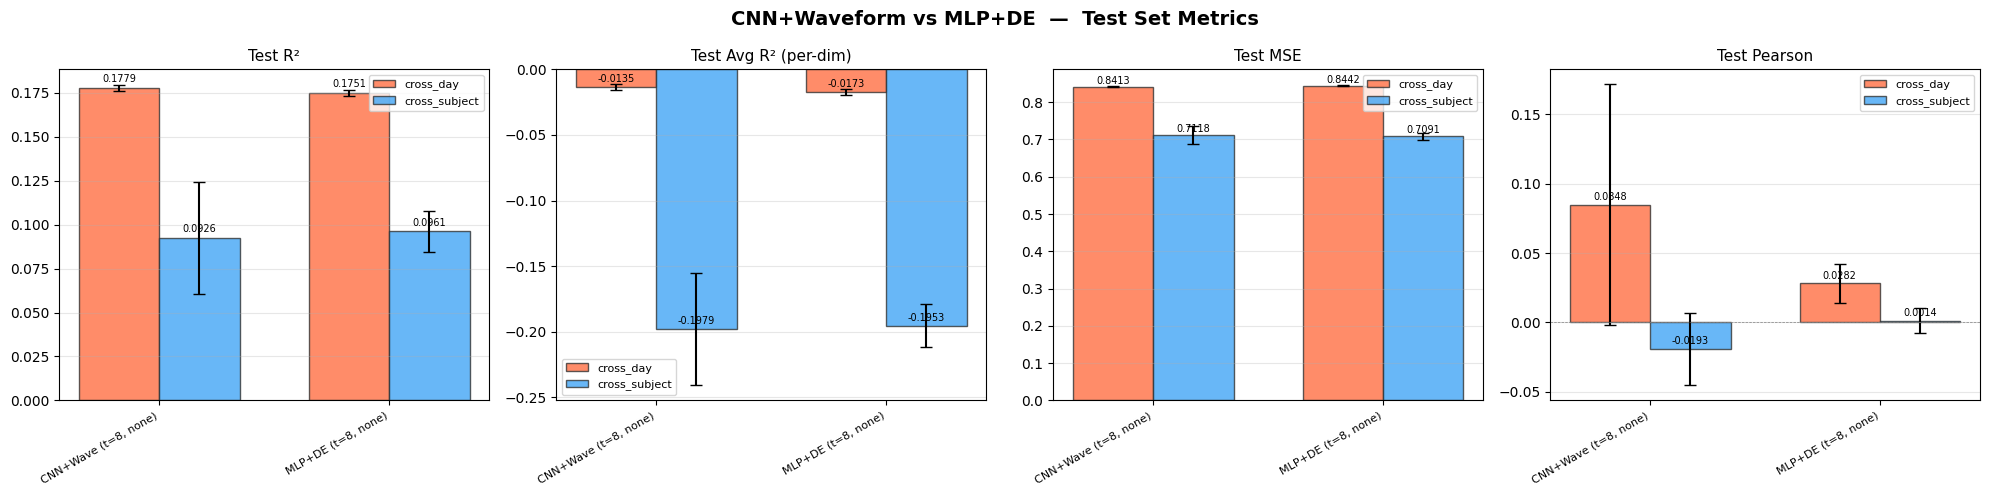

对比图已保存到 /root/zjm/cadt_test_code/report/04.mlp_vs_cnn_comparison.png


In [10]:
# === Cell 4: 柱状图对比 ===
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle('CNN+Waveform vs MLP+DE  —  Test Set Metrics', fontsize=14, fontweight='bold')

for ax, metric, title in zip(axes, 
                              ['test_r2', 'test_avg_r2', 'test_mse', 'test_pearson'],
                              ['Test R²', 'Test Avg R² (per-dim)', 'Test MSE', 'Test Pearson']):
    for i, (split_mode, group) in enumerate(df_cmp.groupby('split_mode')):
        labels = []
        means = []
        stds = []
        for enc_label, sub in group.groupby('encoder_label'):
            labels.append(enc_label)
            means.append(sub[metric].mean())
            stds.append(sub[metric].std() if len(sub) > 1 else 0)
        
        x = np.arange(len(labels))
        width = 0.35
        offset = (i - 0.5) * width
        colors = ['#42A5F5' if split_mode == 'cross_subject' else '#FF7043']
        bars = ax.bar(x + offset, means, width, yerr=stds, capsize=4,
                       label=split_mode, color=colors, alpha=0.8, edgecolor='#333')
        
        for bar, val in zip(bars, means):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                    f'{val:.4f}', ha='center', va='bottom', fontsize=7)
    
    ax.set_xticks(np.arange(len(df_cmp['encoder_label'].unique())))
    ax.set_xticklabels(df_cmp.groupby('encoder_label').size().index, rotation=30, ha='right', fontsize=8)
    ax.set_title(title, fontsize=11)
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)
    ax.axhline(y=0, color='gray', linewidth=0.5, linestyle='--')

plt.tight_layout()
plt.savefig('/root/zjm/cadt_test_code/report/04.mlp_vs_cnn_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("对比图已保存到 /root/zjm/cadt_test_code/report/04.mlp_vs_cnn_comparison.png")

In [11]:
# === Cell 5: 分 split_mode 详细对比表 ===
for sm in ['cross_subject', 'cross_day']:
    sub = df_cmp[df_cmp['split_mode'] == sm]
    print(f"\n{'='*80}")
    print(f"  {sm.upper()}")
    print(f"{'='*80}")
    
    for enc in sub['encoder_label'].unique():
        enc_sub = sub[sub['encoder_label'] == enc]
        print(f"\n  [{enc}]  ({len(enc_sub)} runs)")
        print(f"    Test R²:      {enc_sub['test_r2'].mean():.4f} ± {enc_sub['test_r2'].std():.4f}  "
              f"(range: {enc_sub['test_r2'].min():.4f} ~ {enc_sub['test_r2'].max():.4f})")
        print(f"    Test Avg R²:  {enc_sub['test_avg_r2'].mean():.4f} ± {enc_sub['test_avg_r2'].std():.4f}")
        print(f"    Test MSE:     {enc_sub['test_mse'].mean():.4f} ± {enc_sub['test_mse'].std():.4f}")
        print(f"    Test Pearson: {enc_sub['test_pearson'].mean():.4f} ± {enc_sub['test_pearson'].std():.4f}")



  CROSS_SUBJECT

  [MLP+DE (t=8, none)]  (5 runs)
    Test R²:      0.0961 ± 0.0117  (range: 0.0816 ~ 0.1088)
    Test Avg R²:  -0.1953 ± 0.0161
    Test MSE:     0.7091 ± 0.0091
    Test Pearson: 0.0014 ± 0.0090

  [CNN+Wave (t=8, none)]  (5 runs)
    Test R²:      0.0926 ± 0.0318  (range: 0.0500 ~ 0.1206)
    Test Avg R²:  -0.1979 ± 0.0424
    Test MSE:     0.7118 ± 0.0250
    Test Pearson: -0.0193 ± 0.0260

  CROSS_DAY

  [MLP+DE (t=8, none)]  (5 runs)
    Test R²:      0.1751 ± 0.0017  (range: 0.1723 ~ 0.1766)
    Test Avg R²:  -0.0173 ± 0.0026
    Test MSE:     0.8442 ± 0.0017
    Test Pearson: 0.0282 ± 0.0143

  [CNN+Wave (t=8, none)]  (5 runs)
    Test R²:      0.1779 ± 0.0016  (range: 0.1755 ~ 0.1792)
    Test Avg R²:  -0.0135 ± 0.0021
    Test MSE:     0.8413 ± 0.0016
    Test Pearson: 0.0848 ± 0.0868


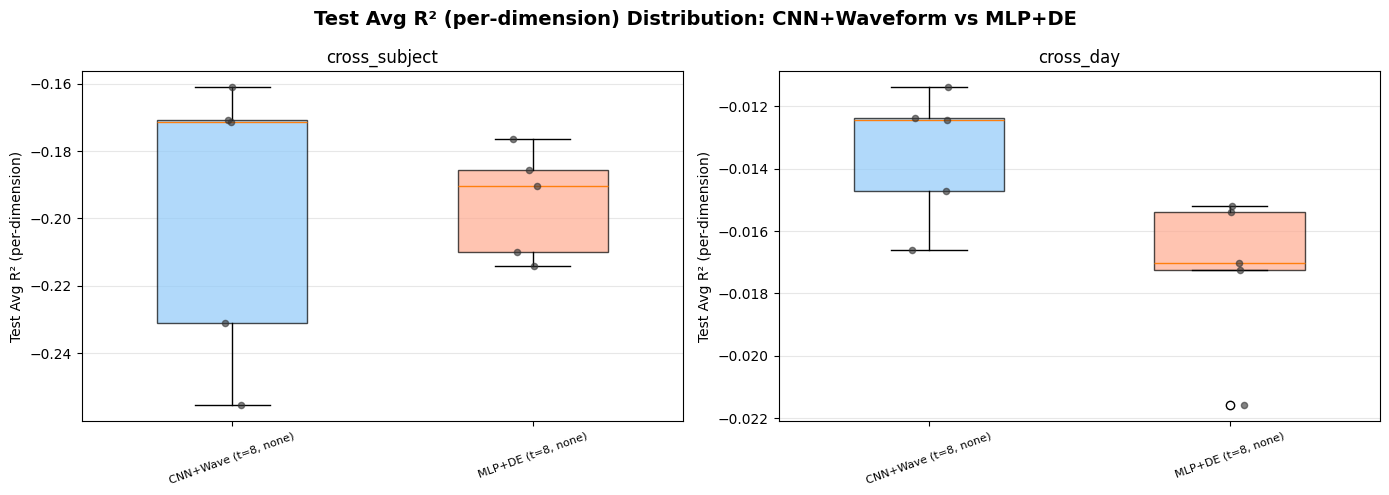

Boxplot 已保存到 /root/zjm/cadt_test_code/report/04.mlp_vs_cnn_boxplot.png


In [12]:
# === Cell 6: Boxplot 对比 (Test Avg R²: per-dimension R² 的平均值) ===
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Test Avg R² (per-dimension) Distribution: CNN+Waveform vs MLP+DE', fontsize=14, fontweight='bold')

for ax, sm in zip(axes, ['cross_subject', 'cross_day']):
    sub = df_cmp[df_cmp['split_mode'] == sm]
    data = []
    labels = []
    for enc in sorted(sub['encoder_label'].unique()):
        data.append(sub[sub['encoder_label'] == enc]['test_avg_r2'].values)
        labels.append(enc)

    bp = ax.boxplot(data, tick_labels=labels, patch_artist=True, widths=0.5)
    colors_box = ['#90CAF9', '#FFAB91', '#A5D6A7', '#CE93D8']
    for patch, color in zip(bp['boxes'], colors_box[:len(bp['boxes'])]):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    ax.set_title(sm, fontsize=12)
    ax.set_ylabel('Test Avg R² (per-dimension)')
    ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='x', rotation=20, labelsize=8)

    # 标注每个点
    for i, d in enumerate(data):
        x = np.random.normal(i + 1, 0.04, size=len(d))
        ax.scatter(x, d, alpha=0.6, color='#333', s=20, zorder=3)

plt.tight_layout()
plt.savefig('/root/zjm/cadt_test_code/report/04.mlp_vs_cnn_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()
print("Boxplot 已保存到 /root/zjm/cadt_test_code/report/04.mlp_vs_cnn_boxplot.png")